# 10 — Recommendation Approach and Risk Factors

**Milestone 4 · Task 11.** Define how model predictions and EDA findings
become recommendations, and identify the factors associated with campaigns
being predicted as at risk.

**Goal of Milestone 4** (from the challenge brief): *explore how predictions
and insights from successful campaigns could be translated into actionable
recommendations for campaigns predicted to be at risk.*

The final model is the **tuned, calibrated Random Forest** on launch-time
features, chosen in Milestone 3 (notebook 09) because it scored best on
accuracy, F1, recall and ROC-AUC. The prototype pairs it with the Milestone 3
**Logistic Regression as an advisor** that estimates what-if effects — §11.8
shows why a forest cannot do that job on its own.

This notebook settles three things before any recommendation is written:

1. What a creator can and cannot change
2. What the evidence says about each thing they can change
3. Why the advice comes from *what-if predictions* rather than from reading
   model coefficients

In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

from src.features import build_model_matrix
from src.modeling import align_columns
from src.evaluation import evaluate, majority_class_baseline
from src.prepare import load_splits
from src.recommend import Recommender, BANDS, EXTRA
from src.modeling import FINAL_MODEL_NAME

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
mpl.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 10})
TEAL, PLUM, CORAL, SAND = "#2E7D6F", "#7B5EA7", "#C0392B", "#D9A455"
FIG = Path("../reports/figures")

train, test = load_splits("..")["random"]
rec = Recommender.fit(train, test=test)
print(f"train {len(train):,}   test {len(test):,}   features {len(rec.columns)}")

train 30,702   test 7,676   features 137


## 11.1 The final model, re-measured

Re-computed here rather than quoted, so this notebook stands on its own.

In [2]:
X_test, y_test = build_model_matrix(test, "launch_only", extra_numeric=EXTRA)
X_test = align_columns(rec.X_train, X_test)
perf = pd.concat([
    majority_class_baseline(train["success"], test["success"]),
    evaluate(rec.model, X_test, y_test, label=FINAL_MODEL_NAME,
             feature_set="launch_only", split="random"),
], ignore_index=True)
perf.round(4)

,model,feature_set,split,accuracy,precision,recall,f1,roc_auc
0,Majority class,—,—,0.5473,0.5473,1.000,0.7074,0.50
1,Random Forest (tuned + calibrated),launch_only,random,0.7187,0.7121,0.816,0.7605,0.78


Roughly 72% accuracy against a 54.7% floor. It is below the 80% in the brief
because that figure was produced with `updates` included, which is not known
at launch (Milestone 3, Task 7). A prototype that advises creators *before*
they launch cannot use it.

## 11.2 Can the probability be trusted?

A recommendation prototype shows a probability to a person, so calibration
matters as much as accuracy. If it says 30%, roughly 30% of campaigns scored
that way should succeed.

                 predicted  observed    n  gap_pp
(0.0595, 0.181]      0.123     0.109  768  -1.327
(0.181, 0.302]       0.239     0.246  768   0.678
(0.302, 0.425]       0.366     0.332  767  -3.359
(0.425, 0.525]       0.478     0.462  768  -1.537
(0.525, 0.606]       0.566     0.544  767  -2.268
(0.606, 0.669]       0.640     0.635  768  -0.419
(0.669, 0.722]       0.697     0.709  767   1.241
(0.722, 0.77]        0.746     0.757  768   1.007
(0.77, 0.819]        0.794     0.811  767   1.719
(0.819, 0.924]       0.850     0.867  768   1.727

Largest gap in any decile: 3.4 percentage points


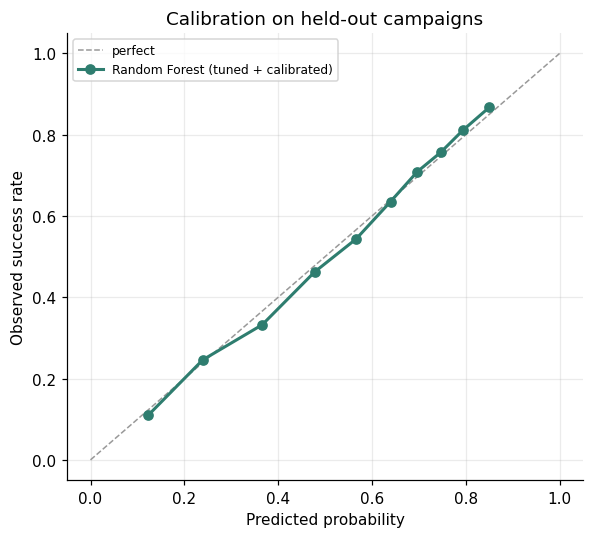

In [3]:
p, y = rec.holdout_p, rec.holdout_y
deciles = pd.qcut(p, 10, duplicates="drop")
cal = (pd.DataFrame({"p": p, "y": y}).groupby(deciles, observed=True)
       .agg(predicted=("p", "mean"), observed=("y", "mean"), n=("y", "size")))
cal["gap_pp"] = (cal["observed"] - cal["predicted"]) * 100
print(cal.round(3).to_string())
print(f"\nLargest gap in any decile: {cal['gap_pp'].abs().max():.1f} percentage points")

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 1], [0, 1], color="#999", ls="--", lw=1, label="perfect")
ax.plot(cal["predicted"], cal["observed"], marker="o", color=TEAL, lw=2,
        label=FINAL_MODEL_NAME)
ax.set_xlabel("Predicted probability"); ax.set_ylabel("Observed success rate")
ax.set_title("Calibration on held-out campaigns"); ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "m4_calibration.png", dpi=130, bbox_inches="tight")
plt.show()

Well calibrated after the sigmoid calibration added in notebook 09 — the
probabilities can be shown to a creator at face value, with the caveat that
individual predictions carry real uncertainty (ROC-AUC is about 0.78, not
0.99).

## 11.3 Risk bands

Three bands, defined by predicted probability. The observed success rate for
each is measured on held-out campaigns, so a band label always comes with
what actually happened to campaigns scored there.

In [4]:
bands = pd.DataFrame([{"band": k, "predicted range": f"{v['range'][0]:.0%} to {v['range'][1]:.0%}",
                       "held-out campaigns": v["n"],
                       "observed success": f"{v['observed_rate']:.1%}"}
                      for k, v in rec.band_rates.items()])
bands

,band,predicted range,held-out campaigns,observed success
0,High risk,0% to 35%,1804,19.7%
1,Moderate risk,35% to 55%,1483,43.4%
2,Favourable,55% to 100%,4389,72.9%


The bands separate cleanly: campaigns scored **High risk** succeeded about
one time in five, while **Favourable** ones succeeded roughly three times in
four. "At risk", for the rest of this milestone, means *High risk* or
*Moderate risk*.

## 11.4 What a creator can and cannot change

Advice is only useful about decisions that are still open. Everything the
model uses is known at launch, but not everything is changeable.

In [5]:
pd.DataFrame([
    ("Goal", "Yes", "Funding target in dollars", "**Lever**"),
    ("Duration", "Yes", "Campaign length in days (1-60)", "**Lever**"),
    ("Reward tiers", "Yes", "Number of tiers and their price points", "**Lever**"),
    ("Category / subcategory", "No", "What the project is", "Informs the prediction only"),
    ("State / city", "No", "Where the creator is based", "Informs the prediction only"),
    ("Launch date", "Partly", "Effect is weak and confounded with platform drift", "Held fixed, never advised"),
    ("Title wording", "Partly", "Weak signal in September's analysis", "Not advised"),
    ("Updates, backers, pledged, comments", "n/a", "Do not exist at launch", "**Cannot enter the tool**"),
], columns=["factor", "changeable?", "what it is", "role in the prototype"])

,factor,changeable?,what it is,role in the prototype
0,Goal,Yes,Funding target in dollars,**Lever**
1,Duration,Yes,Campaign length in days (1-60),**Lever**
2,Reward tiers,Yes,Number of tiers and their price points,**Lever**
3,Category / subcategory,No,What the project is,Informs the prediction only
4,State / city,No,Where the creator is based,Informs the prediction only
5,Launch date,Partly,Effect is weak and confounded with platform drift,"Held fixed, never advised"
6,Title wording,Partly,Weak signal in September's analysis,Not advised
7,"Updates, backers, pledged, comments",n/a,Do not exist at launch,**Cannot enter the tool**


## 11.5 What the evidence says about each lever

All figures use the **training split only**. Where a pattern could be a
side-effect of goal size, it is shown *within goal quartiles* — cheap
projects ask for less and succeed more, so comparing across goal sizes would
mislead.

In [6]:
t = train.copy()
t["goal_q"] = pd.qcut(t["goal"], 4, labels=["Q1 (small)", "Q2", "Q3", "Q4 (large)"])

# --- goal
t["goal_decile"] = pd.qcut(t["goal"], 10, duplicates="drop")
goal_ev = t.groupby("goal_decile", observed=True).agg(
    median_goal=("goal", "median"), success=("success", "mean"), n=("success", "size"))

# --- reward tiers within goal quartile
t["tier_bucket"] = pd.cut(t["levels"], [0, 4, 7, 10, 100], labels=["<=4", "5-7", "8-10", "11+"])
tier_ev = t.pivot_table(index="goal_q", columns="tier_bucket", values="success",
                        aggfunc="mean", observed=True)

# --- duration within goal quartile
t["dur_bucket"] = pd.cut(t["duration_days"], [0, 29.5, 30.5, 45, 100],
                         labels=["<=29", "30 (default)", "31-45", ">45"])
dur_ev = t.pivot_table(index="goal_q", columns="dur_bucket", values="success",
                       aggfunc="mean", observed=True)

# --- entry price: raw gap vs the gap with goal size AND tier count held fixed
t["entry_b"] = pd.cut(t["min_tier"], [0, 10, 25, 1e9], labels=["<=$10", "$11-25", ">$25"])
t["tier_b"] = pd.cut(t["levels"], [0, 4, 7, 100], labels=["<=4", "5-7", "8+"])

def entry_gap(bucket, ref="<=$10", min_cell=30):
    """(raw gap, adjusted gap) in points, bucket minus reference.

    The adjusted gap compares campaigns only within cells of the same goal
    quartile and tier-count band, weighting each cell by the size of `bucket`.
    """
    raw = (t.loc[t["entry_b"] == bucket, "success"].mean()
           - t.loc[t["entry_b"] == ref, "success"].mean()) * 100
    g = t.groupby(["goal_q", "tier_b", "entry_b"], observed=True)["success"].agg(["mean", "size"])
    num = den = 0.0
    for (q, tb), _ in t.groupby(["goal_q", "tier_b"], observed=True):
        try:
            a, r = g.loc[(q, tb, bucket)], g.loc[(q, tb, ref)]
        except KeyError:
            continue
        if a["size"] >= min_cell and r["size"] >= min_cell:
            num += a["size"] * (a["mean"] - r["mean"]); den += a["size"]
    return raw, (num / den) * 100 if den else float("nan")

entry_ev = t.groupby("entry_b", observed=True).agg(
    success=("success", "mean"), n=("success", "size"),
    median_tiers=("levels", "median"), share_4_or_fewer_tiers=("levels", lambda s: (s <= 4).mean()))
entry_gaps = pd.DataFrame(
    {b: entry_gap(b) for b in ["$11-25", ">$25"]}, index=["raw gap (pts)", "gap with goal + tiers held fixed (pts)"]).T

print("GOAL — success by decile"); print(goal_ev.round(3).to_string())
print("\nREWARD TIERS — success by tier count, within goal quartile"); print(tier_ev.round(3).to_string())
print("\nDURATION — success by length, within goal quartile"); print(dur_ev.round(3).to_string())
print("\nENTRY PRICE — by cheapest tier"); print(entry_ev.round(3).to_string())
print("\nENTRY PRICE — gap versus a <=$10 entry, before and after holding goal and tier count fixed")
print(entry_gaps.round(1).to_string())

GOAL — success by decile
                       median_goal  success     n
goal_decile                                      
(0.999, 750.0]               500.0    0.712  3184
(750.0, 1250.0]             1000.0    0.668  3002
(1250.0, 2000.0]            1800.0    0.666  3673
(2000.0, 3000.0]            2700.0    0.625  3989
(3000.0, 4000.0]            3600.0    0.590  2262
(4000.0, 5000.0]            5000.0    0.513  3385
(5000.0, 7000.0]            6000.0    0.524  2057
(7000.0, 10000.0]          10000.0    0.469  3692
(10000.0, 20000.0]         15000.0    0.382  3042
(20000.0, 20000000.0]      35000.0    0.227  2416

REWARD TIERS — success by tier count, within goal quartile
tier_bucket    <=4    5-7   8-10    11+
goal_q                                 
Q1 (small)   0.614  0.694  0.740  0.795
Q2           0.402  0.601  0.678  0.773
Q3           0.153  0.445  0.570  0.687
Q4 (large)   0.074  0.236  0.364  0.515

DURATION — success by length, within goal quartile
dur_bucket   <=29  30 (

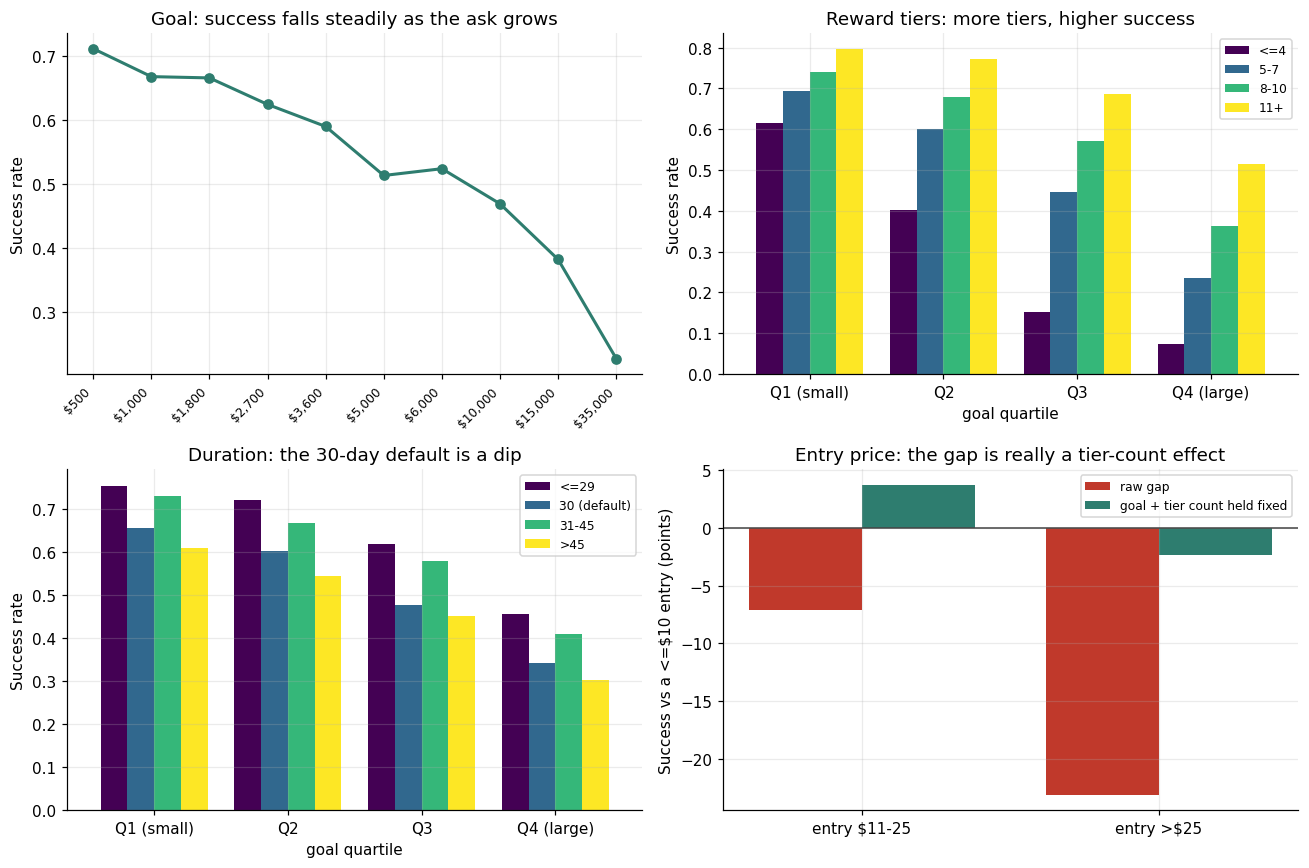

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

ax = axes[0, 0]
ax.plot(range(len(goal_ev)), goal_ev["success"], marker="o", color=TEAL, lw=2)
ax.set_xticks(range(len(goal_ev)))
ax.set_xticklabels([f"${v:,.0f}" for v in goal_ev["median_goal"]], rotation=45, ha="right", fontsize=8)
ax.set_title("Goal: success falls steadily as the ask grows"); ax.set_ylabel("Success rate")

for ax, ev, title in [(axes[0, 1], tier_ev, "Reward tiers: more tiers, higher success"),
                      (axes[1, 0], dur_ev, "Duration: the 30-day default is a dip")]:
    ev.plot.bar(ax=ax, width=0.8, rot=0, colormap="viridis")
    ax.set_title(title); ax.set_ylabel("Success rate"); ax.set_xlabel("goal quartile")
    ax.legend(fontsize=8, title=None)

ax = axes[1, 1]
x = np.arange(len(entry_gaps)); w = 0.38
ax.bar(x - w / 2, entry_gaps.iloc[:, 0], w, color=CORAL, label="raw gap")
ax.bar(x + w / 2, entry_gaps.iloc[:, 1], w, color=TEAL, label="goal + tier count held fixed")
ax.axhline(0, color="#444", lw=1)
ax.set_xticks(x); ax.set_xticklabels([f"entry {b}" for b in entry_gaps.index])
ax.set_ylabel("Success vs a <=$10 entry (points)")
ax.set_title("Entry price: the gap is really a tier-count effect"); ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(FIG / "m4_lever_evidence.png", dpi=130, bbox_inches="tight")
plt.show()

### Reading the evidence

- **Goal** — a clean, monotonic decline. The most reliable relationship in
  the data.
- **Reward tiers** — the strongest effect, and it survives every goal
  quartile. A large-goal campaign with four or fewer tiers succeeds a small
  fraction of the time; with eleven or more it succeeds about half the time.
- **Duration** — longer campaigns do worse, **and exactly-30-day campaigns
  are a dip** relative to neighbouring durations, within every goal
  quartile. See §11.6.
- **Entry price** — campaigns with a high entry price do succeed less, but
  they also offer far fewer tiers (see the table above). Holding goal size
  and tier count fixed, the gap shrinks from -23 points to a few points, and
  its sign changes between buckets. **Entry price is not a separate lever;
  the tier count is.**

## 11.6 Four September statements that did not survive checking

While designing the levers, each claim from the September EDA that the
recommendations would lean on was re-tested against the data. Four were
wrong or overstated. They are corrected here and should be corrected in the
README and `04_eda.ipynb`.

In [8]:
full = pd.concat([train, test])
is30 = full["is_30_day"] == 1
min_hi = full["min_tier"] > 25
cheap = full.loc[full["min_tier"] <= 10, "success"].mean()

hi_gap = entry_gaps.loc[">$25"]
mid_gap = entry_gaps.loc["$11-25"]

# live check of the "just add a cheap tier" advice
from src.recommend import tiers_to_string, string_to_tiers
_raw = test[["goal", "duration", "levels", "reward_levels", "category", "subcategory",
             "state_raw", "city", "launch_date", "name"]].copy()
_tiers = _raw["reward_levels"].map(string_to_tiers)
_m = _tiers.map(min).gt(25).to_numpy()
_new = [tiers_to_string(sorted(set(x + [10.0]))) if mm else s_
        for x, s_, mm in zip(_tiers, _raw["reward_levels"], _m)]
_r2 = _raw.copy(); _r2["reward_levels"] = _new; _r2["levels"] = [len(string_to_tiers(v)) for v in _new]
add_tier_gain = ((rec.what_if_proba(_raw, _r2) - rec.predict_proba(_raw)) * 100)[_m].mean()

# --- location: September called it modest, "a few points between best and worst states"
from scipy.stats import spearmanr
st = train.groupby("state_raw")["success"].agg(["mean", "size"])
st = st[st["size"] >= 150].sort_values("mean")
_gq = pd.qcut(train["goal"], 4, labels=False)
_res = (train["success"] - train.groupby(_gq)["success"].transform("mean"))
st_adj = _res.groupby(train["state_raw"]).agg(["mean", "size"])
st_adj = st_adj[st_adj["size"] >= 150]["mean"] * 100
city_q = train.groupby(pd.qcut(train["city_project_count"].rank(method="first"), 4,
                               labels=["smallest", "small-mid", "large-mid", "largest"]),
                       observed=True)["success"].mean()
rho_city = spearmanr(train["log_city_project_count"], train["success"]).statistic

corrections = pd.DataFrame([
    {"September statement": "The 30-day default outperforms",
     "what the data shows": (f"30-day campaigns succeed {full.loc[is30, 'success'].mean():.1%} "
                             f"vs {full.loc[~is30, 'success'].mean():.1%} for all others, and "
                             f"clearly less than 26-29 day campaigns within every goal quartile"),
     "verdict": "WRONG"},
    {"September statement": "A low entry price helps",
     "what the data shows": (f"Raw gap for a >$25 entry is {hi_gap.iloc[0]:+.1f} points, but "
                             f"{hi_gap.iloc[1]:+.1f} once goal size and tier count are held "
                             f"fixed. High-entry campaigns offer a median of "
                             f"{entry_ev.loc['>$25', 'median_tiers']:.0f} tiers vs "
                             f"{entry_ev.loc['<=$10', 'median_tiers']:.0f}"),
     "verdict": "OVERSTATED - it is a tier-count effect"},
    {"September statement": "Creators can simply add a $5 tier",
     "what the data shows": (f"Adding a $10 tier to campaigns with a >$25 entry moves the "
                             f"prediction by only {add_tier_gain:+.1f} points; what helps is "
                             f"the number of tiers, not how cheap the cheapest one is"),
     "verdict": "NOT SUPPORTED as stated"},
    {"September statement": "Location is a modest signal (a few points between best and worst states; city density weak)",
     "what the data shows": (f"Across {len(st)} states with 150+ campaigns success runs from "
                             f"{st['mean'].iloc[0]:.0%} ({st.index[0]}) to {st['mean'].iloc[-1]:.0%} "
                             f"({st.index[-1]}), a {(st['mean'].iloc[-1] - st['mean'].iloc[0]) * 100:.0f}-point "
                             f"spread that is {st_adj.max() - st_adj.min():.0f} points after removing goal size. "
                             f"By city size the smallest quartile succeeds {city_q.iloc[0]:.0%} against "
                             f"{city_q.iloc[-1]:.0%} for the largest. A rank correlation of {rho_city:.2f} "
                             f"made it look weak; the rates show it is not"),
     "verdict": "WRONG"},
])
corrections

,September statement,what the data shows,verdict
0,The 30-day default outperforms,30-day campaigns succeed 52.9% vs 55.5% for al...,WRONG
1,A low entry price helps,"Raw gap for a >$25 entry is -23.1 points, but ...",OVERSTATED - it is a tier-count effect
2,Creators can simply add a $5 tier,Adding a $10 tier to campaigns with a >$25 ent...,NOT SUPPORTED as stated
3,Location is a modest signal (a few points betw...,Across 32 states with 150+ campaigns success r...,WRONG


"More reward tiers help" **does** hold, strongly, and it is what the
recommendations lean on instead.

The lesson is worth keeping for the write-up: the September notebook printed
the correct numbers, but the interpretive sentence beside them had been
written before they were read. Findings in this project are now stated
from computed output, not the other way round.

## 11.7 Factors associated with campaigns predicted at risk

What do campaigns the model scores as high or moderate risk have in common?
This describes what the model sees as risky — it is *not* independent
evidence, since the bands were built from these same features. The
independent evidence is §11.5.

In [9]:
tt = test.copy()
tt["p"] = rec.holdout_p
tt["band"] = pd.cut(tt["p"], [0, BANDS[0][0], BANDS[1][0], 1.01],
                    labels=[b[1] for b in BANDS], right=False)

profile = tt.groupby("band", observed=True).agg(
    campaigns=("success", "size"),
    observed_success=("success", "mean"),
    median_goal=("goal", "median"),
    median_duration=("duration_days", "median"),
    median_tiers=("levels", "median"),
    share_4_or_fewer_tiers=("levels", lambda s: (s <= 4).mean()),
    share_over_45_days=("duration_days", lambda s: (s > 45).mean()),
    median_entry_price=("min_tier", "median"),
)
profile.round(3).T

band,High risk,Moderate risk,Favourable
campaigns,1804.000,1483.000,4389.000
observed_success,0.197,0.434,0.729
median_goal,10000.000,5000.000,2500.000
median_duration,40.000,37.000,30.040
median_tiers,6.000,7.000,8.000
share_4_or_fewer_tiers,0.299,0.171,0.095
share_over_45_days,0.391,0.365,0.209
median_entry_price,5.000,5.000,5.000


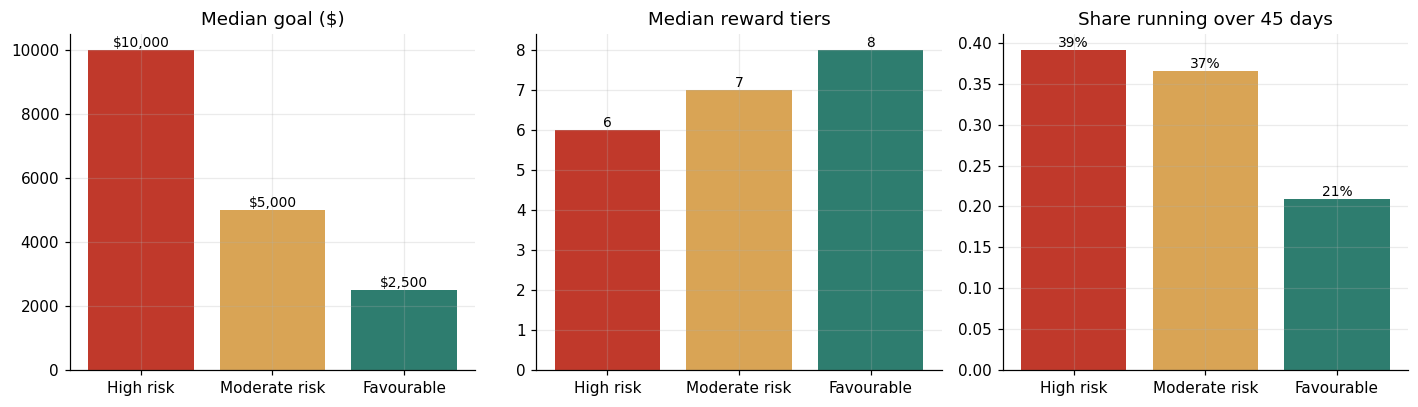

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
order = [b[1] for b in BANDS]
colors = [CORAL, SAND, TEAL]
for ax, col, title, fmt in [
    (axes[0], "median_goal", "Median goal ($)", "${:,.0f}"),
    (axes[1], "median_tiers", "Median reward tiers", "{:.0f}"),
    (axes[2], "share_over_45_days", "Share running over 45 days", "{:.0%}")]:
    vals = profile.loc[order, col]
    ax.bar(order, vals, color=colors)
    ax.set_title(title)
    for i, v in enumerate(vals):
        ax.text(i, v, fmt.format(v), ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.savefig(FIG / "m4_at_risk_profile.png", dpi=130, bbox_inches="tight")
plt.show()

At-risk campaigns ask for more, offer fewer reward tiers, and run longer —
which are exactly the three levers.

**Subcategories most often scored High risk** (at least 80 held-out
campaigns):

In [11]:
sub = tt.groupby("subcategory").agg(n=("p", "size"),
                                    high_risk_share=("band", lambda s: (s == "High risk").mean()),
                                    observed_success=("success", "mean"))
sub[sub["n"] >= 80].sort_values("high_risk_share", ascending=False).head(8).round(3)

,n,high_risk_share,observed_success
subcategory,,,
Product Design,164,0.512,0.354
Nonfiction,151,0.490,0.377
Video Games,136,0.463,0.360
Children's Book,108,0.426,0.306
Publishing,117,0.385,0.342
Fiction,179,0.374,0.380
Documentary,603,0.367,0.478
Fashion,222,0.365,0.293


Category is not a lever, so this does not become advice. It does matter for
*framing*: a creator in a hard subcategory should be told the base rate is
low there, so that a modest predicted probability is read in context.

## 11.8 Why the advice comes from what-ifs, and from an advisor model

Two shortcuts look tempting and both fail.

**Shortcut 1: read the Logistic Regression coefficients** — "goal has a
negative coefficient, so lower it".

In [12]:
coef = pd.Series(rec.advisor.named_steps["clf"].coef_[0], index=rec.columns)
family = ["log_goal", "log_goal_per_tier", "log_goal_per_day",
          "log_goal_vs_subcat_median", "levels", "n_tiers_parsed",
          "duration_days", "is_30_day"]
coef[family].round(3).to_frame("coefficient (per std dev)")

,coefficient (per std dev)
log_goal,1.120
log_goal_per_tier,-1.154
log_goal_per_day,-0.473
log_goal_vs_subcat_median,-0.295
levels,0.105
n_tiers_parsed,0.105
duration_days,-0.430
is_30_day,-0.136


`log_goal` and `log_goal_per_tier` have large coefficients with **opposite
signs**. Taken separately they say opposite things about goal. They are
nearly the same quantity — `goal_per_tier` is the goal divided by the tier
count — so the model splits one effect across several columns with offsetting
signs. `levels` and `n_tiers_parsed` are exact duplicates, so their
coefficients are arbitrary halves of one number. Individual coefficients
cannot be read as advice.

**Shortcut 2: ask the final model directly** — rebuild every goal-derived
feature, re-score with the Random Forest, and report the difference. This
answers the right question, but a forest is a sum of step functions: nudging
one input can cross a split threshold in some trees and land in a slightly
worse leaf. Measured on every held-out campaign:

In [13]:
raw_test = test[["goal", "duration", "levels", "reward_levels", "category", "subcategory",
                 "state_raw", "city", "launch_date", "name"]]
base = rec.predict_proba(raw_test)
rows = []
for f in [0.9, 0.75, 0.5]:
    changed = rec.apply_lever(raw_test, "goal", f)
    rf_after = rec.predict_proba(changed)                     # Random Forest re-scored directly
    adv_after = rec.what_if_proba(raw_test, changed, base=base)  # advisor's effect applied to RF score
    rows.append({"change": f"goal x {f}",
                 "RF direct: share LOWERED": np.mean(rf_after < base),
                 "RF direct: mean change (pts)": (rf_after - base).mean() * 100,
                 "advisor: share lowered": np.mean(adv_after < base),
                 "advisor: mean change (pts)": (adv_after - base).mean() * 100})
whatif_cmp = pd.DataFrame(rows)
whatif_cmp.round(3)

,change,RF direct: share LOWERED,RF direct: mean change (pts),advisor: share lowered,advisor: mean change (pts)
0,goal x 0.9,0.187,1.669,0.001,1.248
1,goal x 0.75,0.126,4.046,0.001,3.537
2,goal x 0.5,0.109,8.324,0.001,8.267


Re-scored directly, the forest says that **cutting the goal makes success
less likely** for a noticeable share of campaigns — advice that contradicts
both the data (§11.5: success falls steadily as the goal rises) and itself.
On average the two approaches agree on the size of the effect; they differ in
consistency.

**The design that follows:**

- The **Random Forest scores** the campaign — the chance and the risk band
  shown to the creator come from the final model.
- The **Logistic Regression advises** — for each candidate change it
  estimates how many percentage points the change is worth, with every
  derived feature rebuilt from the raw inputs, and that change is added to
  the forest's score: `new chance = RF chance + (LR after − LR before)`.
  Its response is smooth and monotonic, so the same change always points the
  same way.
- **Why points rather than log-odds:** the forest cannot extrapolate. A
  $5,000,000 goal and a $60,000 goal land in the same leaves, so both score
  around 6%. Where the advisor sees a campaign as hopeless its points change
  is tiny, so the engine never promises a large gain to a campaign the
  forest merely cannot tell apart from a large one.

## 11.9 The approach

| Step | What it does | Where it is built |
|---|---|---|
| 1. Score | The final Random Forest predicts the chance of success from launch-time inputs; place it in a risk band with the observed rate for that range | `Recommender.assess` |
| 2. Locate | Compare goal, duration and tiers with comparable campaigns in the same subcategory | `Recommender.standing` |
| 3. What-if | Change one lever at a time, rebuild every derived feature, and estimate the effect with the advisor (its change in points, added to the RF score) | `Recommender._candidates`, `what_if_proba` |
| 4. Choose | Recommend the **mildest** change per lever that clears a 2-point gain | `MIN_GAIN` |
| 5. Combine | Apply the chosen changes together and re-estimate (effects are not simply additive) | `Assessment.plan` |
| 6. Qualify | State trade-offs and the limits of what the data can say | `Recommender._notes` |

Design commitments, each enforced in code rather than promised:

- **Launch-time information only.** `updates`, `backers`, `pledged`,
  `comments` and `funded_percentage` have no input slot, and passing one
  raises an error.
- **Only changeable factors are advised.** Category and location inform the
  prediction but are never recommended.
- **Milder changes first.** A small change a creator might actually make
  beats the largest predicted gain.
- **Associations, not causes.** Every report says so.

In [14]:
cal.to_csv("../reports/m4_calibration.csv")
bands.to_csv("../reports/m4_risk_bands.csv", index=False)
profile.round(4).to_csv("../reports/m4_at_risk_profile.csv")
corrections.to_csv("../reports/m4_sept_claims_rechecked.csv", index=False)
print("Wrote m4_calibration, m4_risk_bands, m4_at_risk_profile, m4_sept_claims_rechecked")

Wrote m4_calibration, m4_risk_bands, m4_at_risk_profile, m4_sept_claims_rechecked


## Task 11 — Summary

- **Final model:** tuned, calibrated Random Forest, ~72% accuracy against a
  54.7% floor, well calibrated (worst decile off by a few points).
- **Risk bands** separate cleanly: about one in five High-risk campaigns
  succeeded, against about three in four Favourable ones.
- **Three levers** — goal, duration, number of reward tiers — are the only things a
  creator controls that carry real signal. Reward tiers is the strongest.
- **Four September claims corrected:** the 30-day default does *not*
  outperform; "a low entry price helps" is really a tier-count effect;
  "just add a $5 tier" is not supported advice; and location is **not** a
  modest signal (a ~27-point spread across states).
- **Neither coefficients nor direct forest re-scoring make good advice** —
  the first because the goal features are collinear, the second because a
  forest's response to a small change is not consistent in direction. The
  prototype scores with the forest and estimates what-if effects with the
  Logistic Regression advisor.

**Next:** `11_recommendation_logic.ipynb` builds and stress-tests the rules
that connect predictions to recommendations.